# Machine Learning Supervisado — Regresión Logística y Clasificación
**Universidad de Cundinamarca — Esp. Inteligencia Artificial**
**CADI – Introducción a Machine Learning — Periodo 2026-2**
Docente: Ing. Wilson Rojas Reales, PhD(c)

> Repositorio: https://github.com/Yohann0011/ml-supervisado-clasificacion-ucundinamarca
> Este notebook se ejecuta de extremo a extremo en **Google Colab** (runtime CPU).

# Notebook 02 — Rotación de empleados

**Objetivo:** predecir renuncia (1) / permanencia (0) con edad, salario (log10),
permanencia, satisfacción y horas extras; comparar los seis clasificadores y evaluar el
aporte de clima laboral y modalidad de trabajo (pregunta 6 de la guía).


In [1]:
try:
    import google.colab  # noqa
    EN_COLAB = True
    !git clone --depth 1 https://github.com/Yohann0011/ml-supervisado-clasificacion-ucundinamarca repo 2>/dev/null
    import os
    if os.path.isdir('repo'): os.chdir('repo')
except Exception:
    EN_COLAB = False

import os, sys
from pathlib import Path
RAIZ = Path(os.environ.get('RAIZ_ML', '.'))
for p in (str(RAIZ), str(RAIZ / 'src')):
    if p not in sys.path:
        sys.path.insert(0, p)

%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
from config import SEED, DIR_DATA, DIR_FIGS
print('Semilla:', SEED, '| datos en:', DIR_DATA)


OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k


OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k


Semilla: 42 | datos en: /tmp/arena/tenants/e8826d75-4142-4def-a7d6-6372192c98b1/sessions/36353820-3eae-42c9-a669-90aac76b7923/workspace/ml_informe/../ml_informe/data


In [2]:
df = pd.read_csv(DIR_DATA / 'caso_rrhh.csv')
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
empleado_id,1200.0,600.50,346.55,1.00,300.75,600.50,900.25,1200.0
edad,1200.0,36.03,8.16,21.00,30.00,36.00,42.00,63.0
salario,1200.0,3320012.50,843491.83,1300000.00,2722250.00,3303000.00,3876250.00,6313000.0
salario_log10,1200.0,6.51,0.12,6.11,6.43,6.52,6.59,6.8
anos_permanencia,1200.0,4.77,4.25,0.30,1.60,3.65,6.70,32.0
satisfaccion,1200.0,5.89,1.93,1.00,4.60,5.90,7.20,10.0
horas_extras,1200.0,5.72,3.95,0.00,2.80,4.90,7.80,22.0
clima_laboral,1200.0,6.35,1.95,1.00,5.10,6.30,7.80,10.0
modalidad_trabajo,1200.0,0.70,0.77,0.00,0.00,1.00,1.00,2.0
renuncia,1200.0,0.22,0.41,0.00,0.00,0.00,0.00,1.0


In [3]:
print(df.renuncia.value_counts(normalize=True).round(4))

renuncia
0    0.7808
1    0.2192
Name: proportion, dtype: float64


In [4]:
from analisis import ejecutar_caso
base = ['edad','salario_log10','anos_permanencia','satisfaccion','horas_extras']
res = ejecutar_caso('Rotación de empleados', df, 'renuncia', {0:'Permanece',1:'Renuncia'}, 'rrhh', features=base, features_extra=['clima_laboral','modalidad_trabajo'])


##########################################################################
# CASO: Rotación de empleados
# n = 1200 | variables = 5 | clase positiva = 21.92%
##########################################################################
Train: (960, 5) (positivos 21.88%) | Test: (240, 5) (positivos 22.08%)
Línea base (clase mayoritaria = 0): accuracy = 0.7792


OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k
OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k
OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k


OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k
OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k



>>> Regresión Logística
    Acc=0.833 Prec=0.597 Rec=0.755 F1=0.667 AUC=0.884 AP=0.745 Esp=0.856 MCC=0.564
    CM [TN=160 FP=27 FN=13 TP=40] | CV-F1=0.626±0.033 | gap overfitting=-0.046

>>> Árbol de Decisión
    Acc=0.812 Prec=0.600 Rec=0.453 F1=0.516 AUC=0.684 AP=0.393 Esp=0.914 MCC=0.409
    CM [TN=171 FP=16 FN=29 TP=24] | CV-F1=0.493±0.052 | gap overfitting=+0.188



>>> Random Forest
    Acc=0.871 Prec=0.720 Rec=0.679 F1=0.699 AUC=0.875 AP=0.751 Esp=0.925 MCC=0.617
    CM [TN=173 FP=14 FN=17 TP=36] | CV-F1=0.607±0.032 | gap overfitting=+0.127


...

    [GridSearch] SVM: {'clf__C': 10, 'clf__gamma': 0.01} -> F1_cv=0.631 | F1_test=0.678 Rec=0.755 AUC=0.887


    [GridSearch] KNN: {'clf__n_neighbors': 15} -> F1_cv=0.531 | F1_test=0.550 Rec=0.415 AUC=0.861


    [GridSearch] Naive Bayes: {'clf__var_smoothing': 1e-09} -> F1_cv=0.575 | F1_test=0.581 Rec=0.472 AUC=0.873


    [Pregunta 6] Modelo base (5 variables): mejor=Random Forest F1=0.699 AUC=0.875


    [Pregunta 6] Modelo ampliado (+2 variables): mejor=Random Forest F1=0.680 AUC=0.885


In [5]:
res.tabla_metricas().round(3)

,Modelo,Accuracy,Bal. Acc.,Precision,Recall,F1-Score,Especificidad,AUC-ROC,AP (PR-AUC),Acc. train,Acc. CV-5,σ CV
0,Random Forest,0.871,0.802,0.720,0.679,0.699,0.925,0.875,0.751,0.998,0.606,0.032
1,Regresión Logística,0.833,0.805,0.597,0.755,0.667,0.856,0.884,0.745,0.788,0.626,0.033
2,SVM,0.829,0.802,0.588,0.755,0.661,0.850,0.867,0.707,0.805,0.607,0.033
3,KNN,0.858,0.727,0.788,0.491,0.605,0.963,0.841,0.691,1.000,0.518,0.040
4,Naive Bayes,0.850,0.714,0.758,0.472,0.581,0.957,0.873,0.707,0.835,0.575,0.030
5,Árbol de Decisión,0.812,0.684,0.600,0.453,0.516,0.914,0.684,0.392,1.000,0.493,0.052


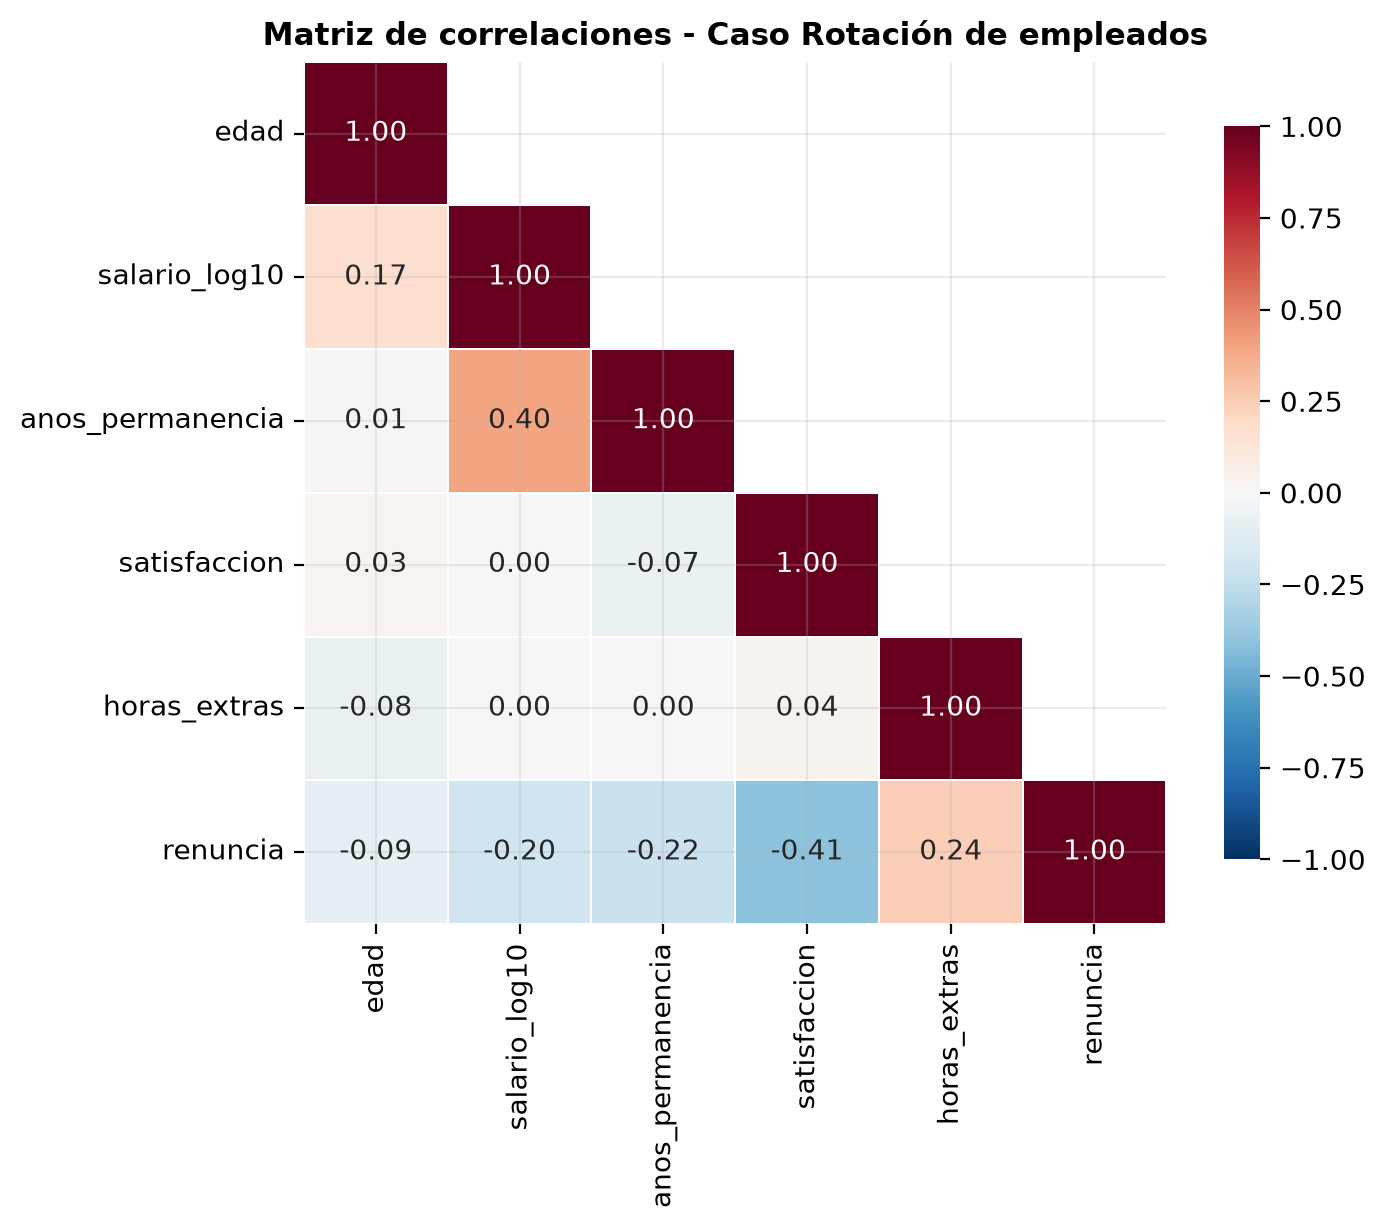

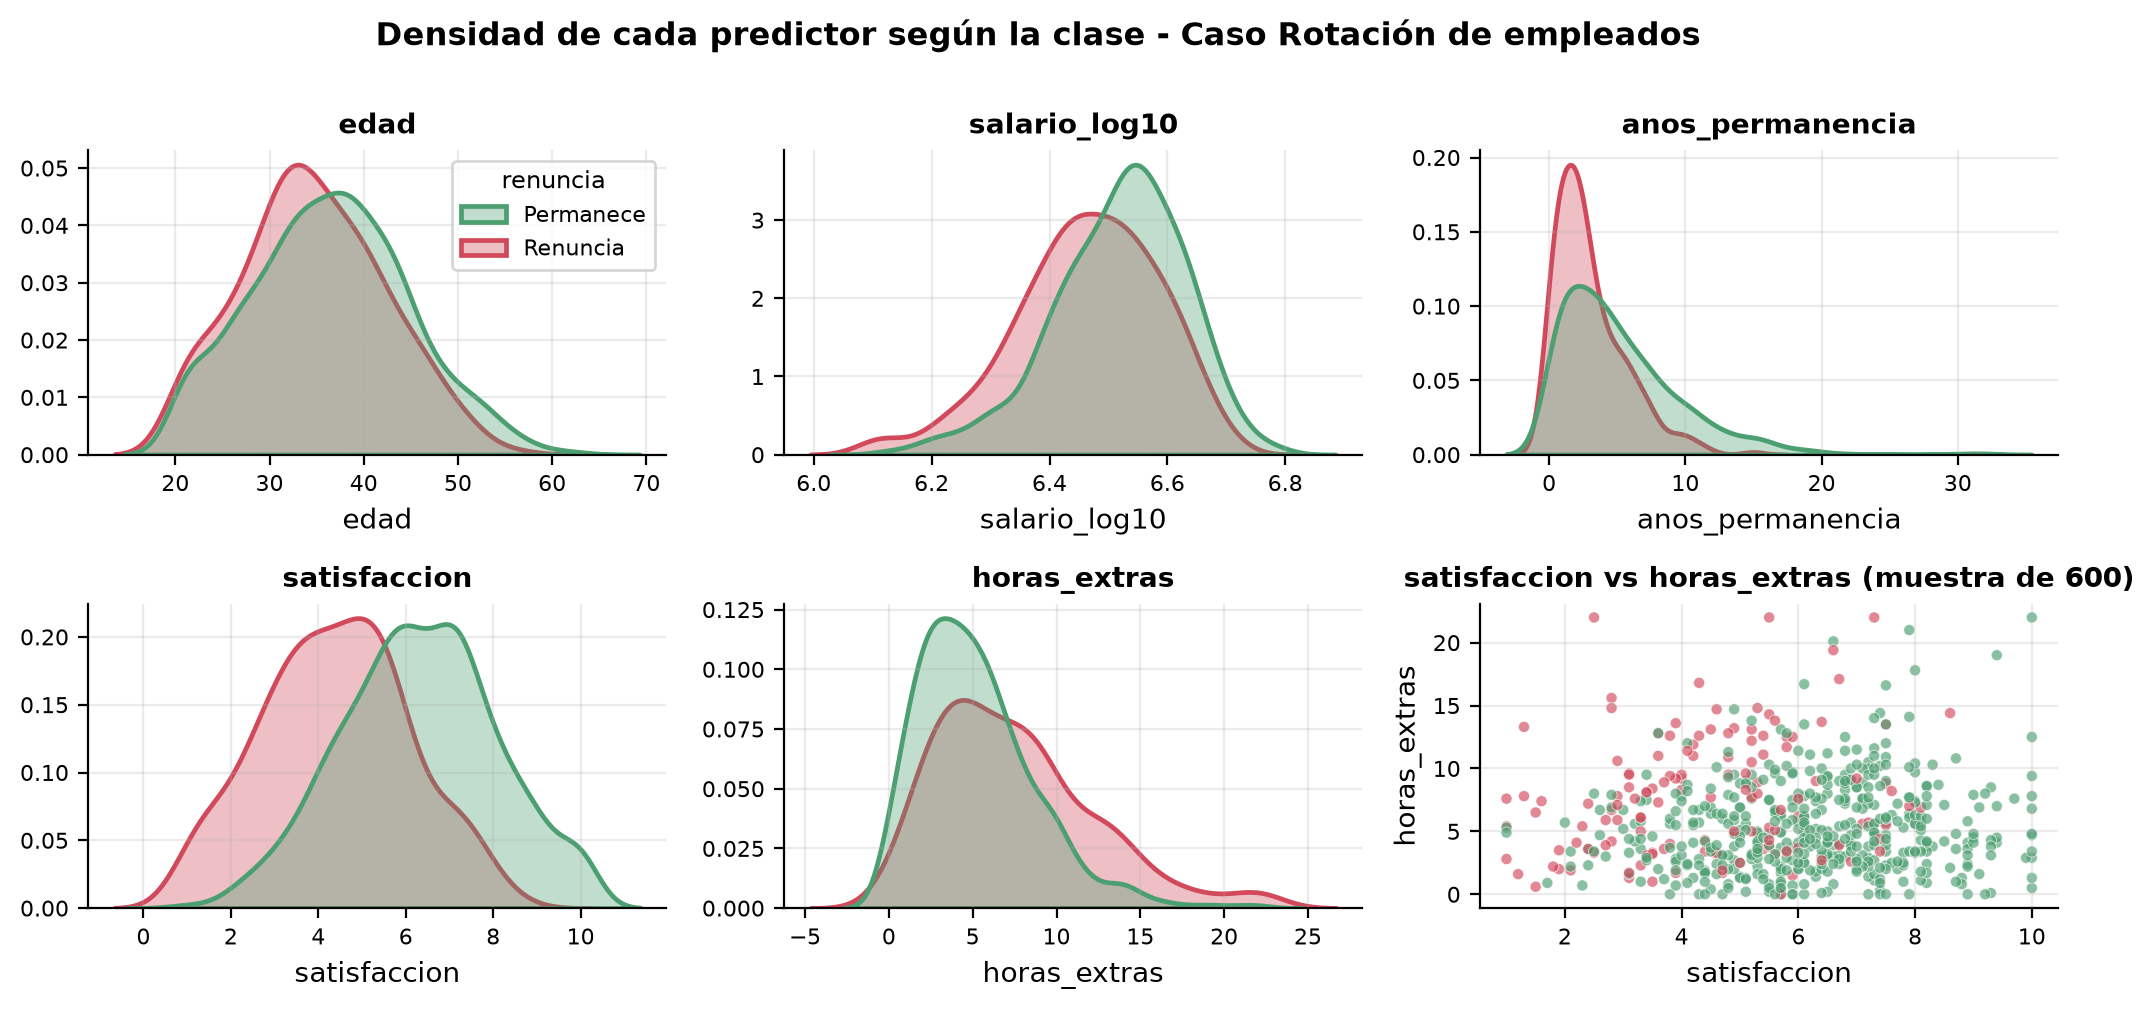

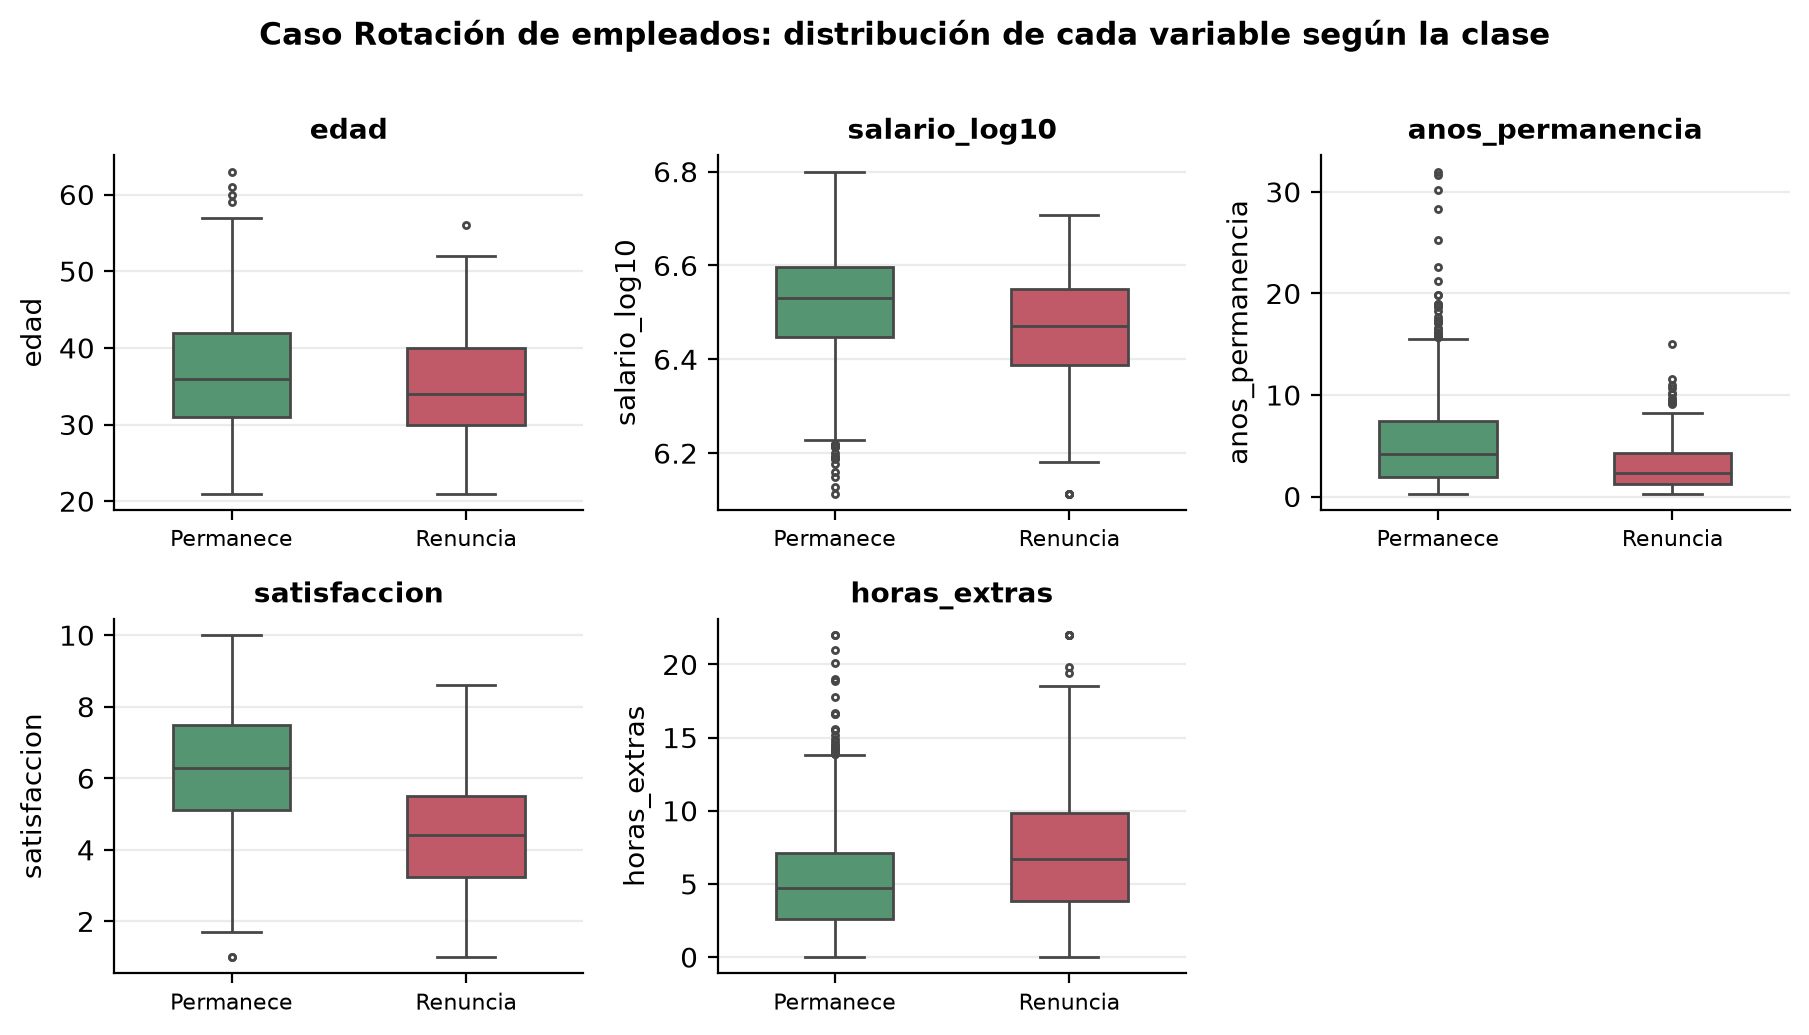

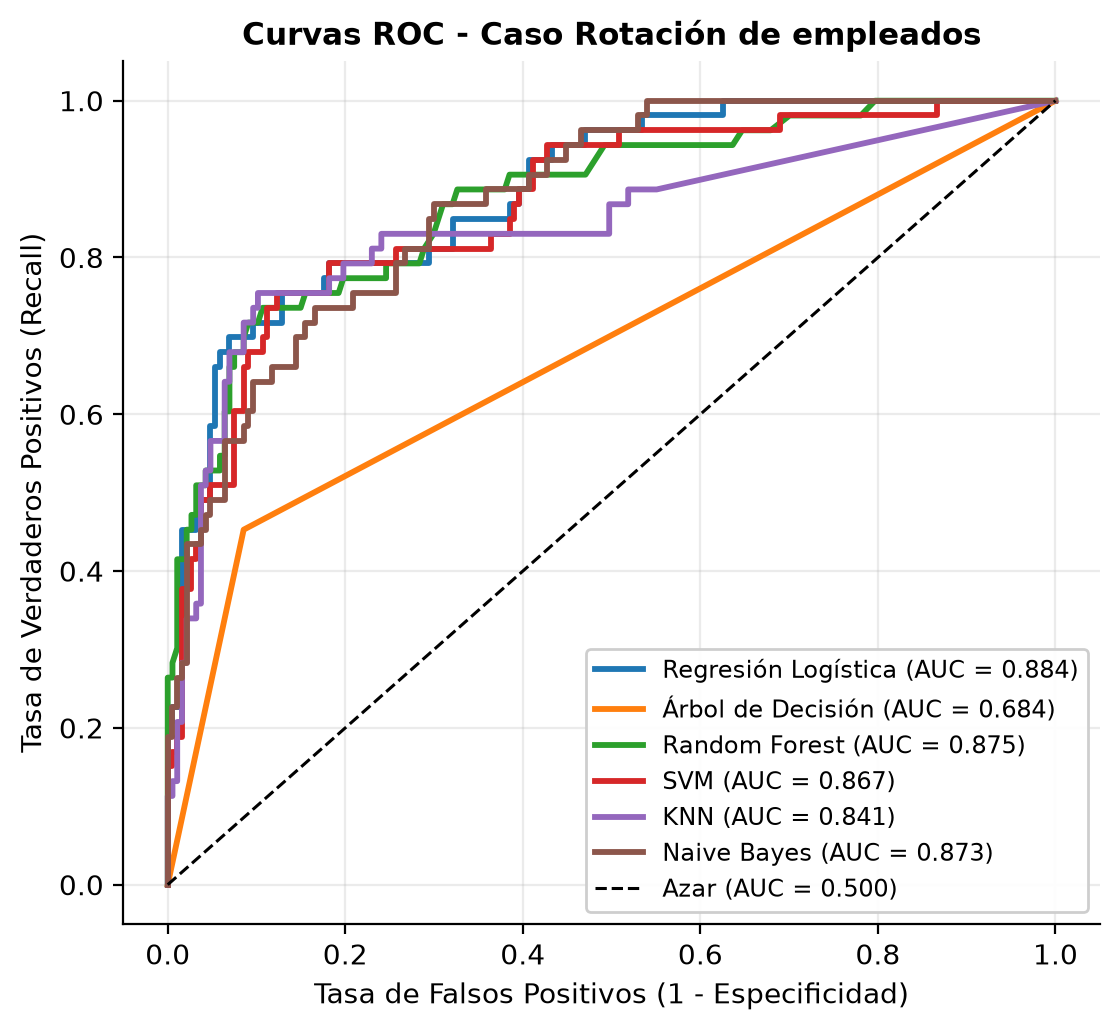

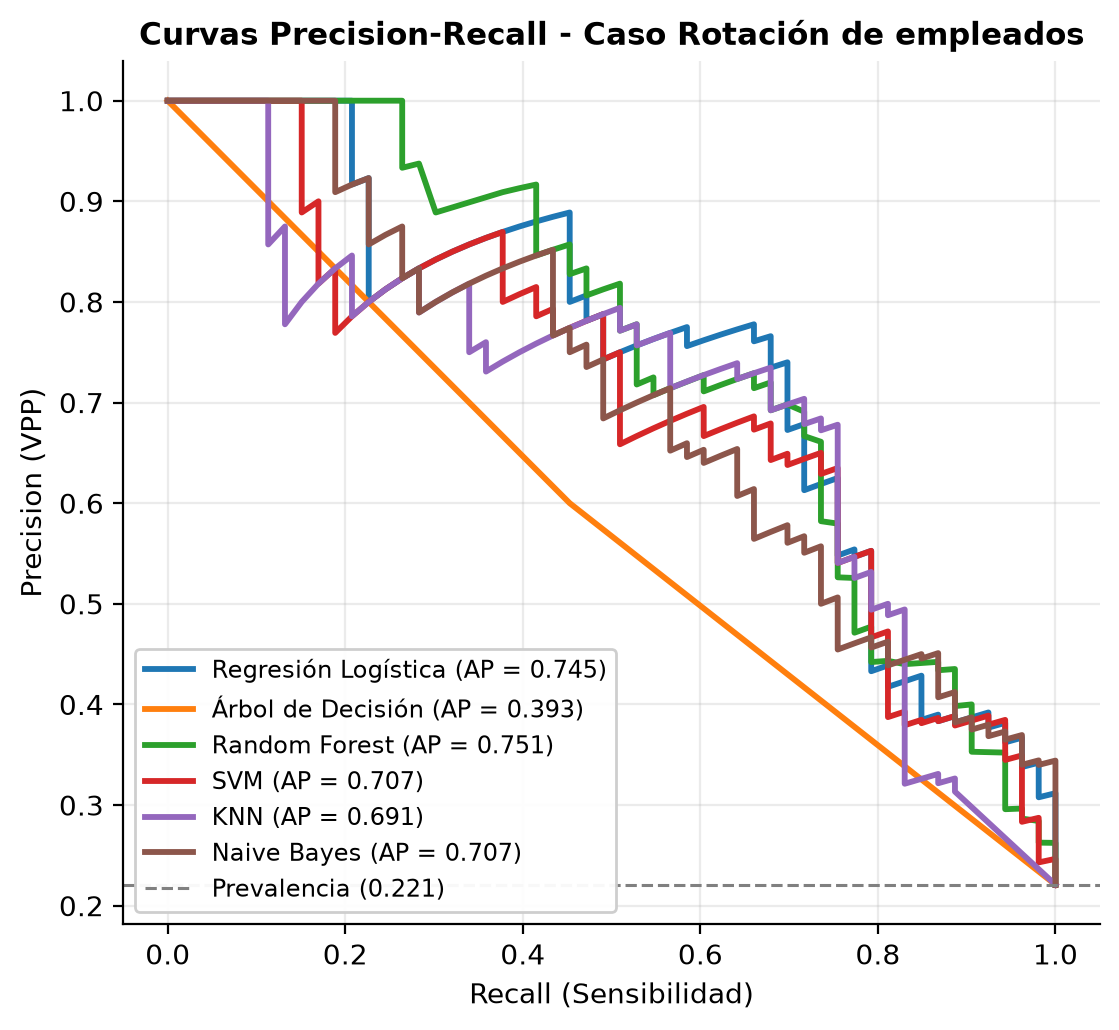

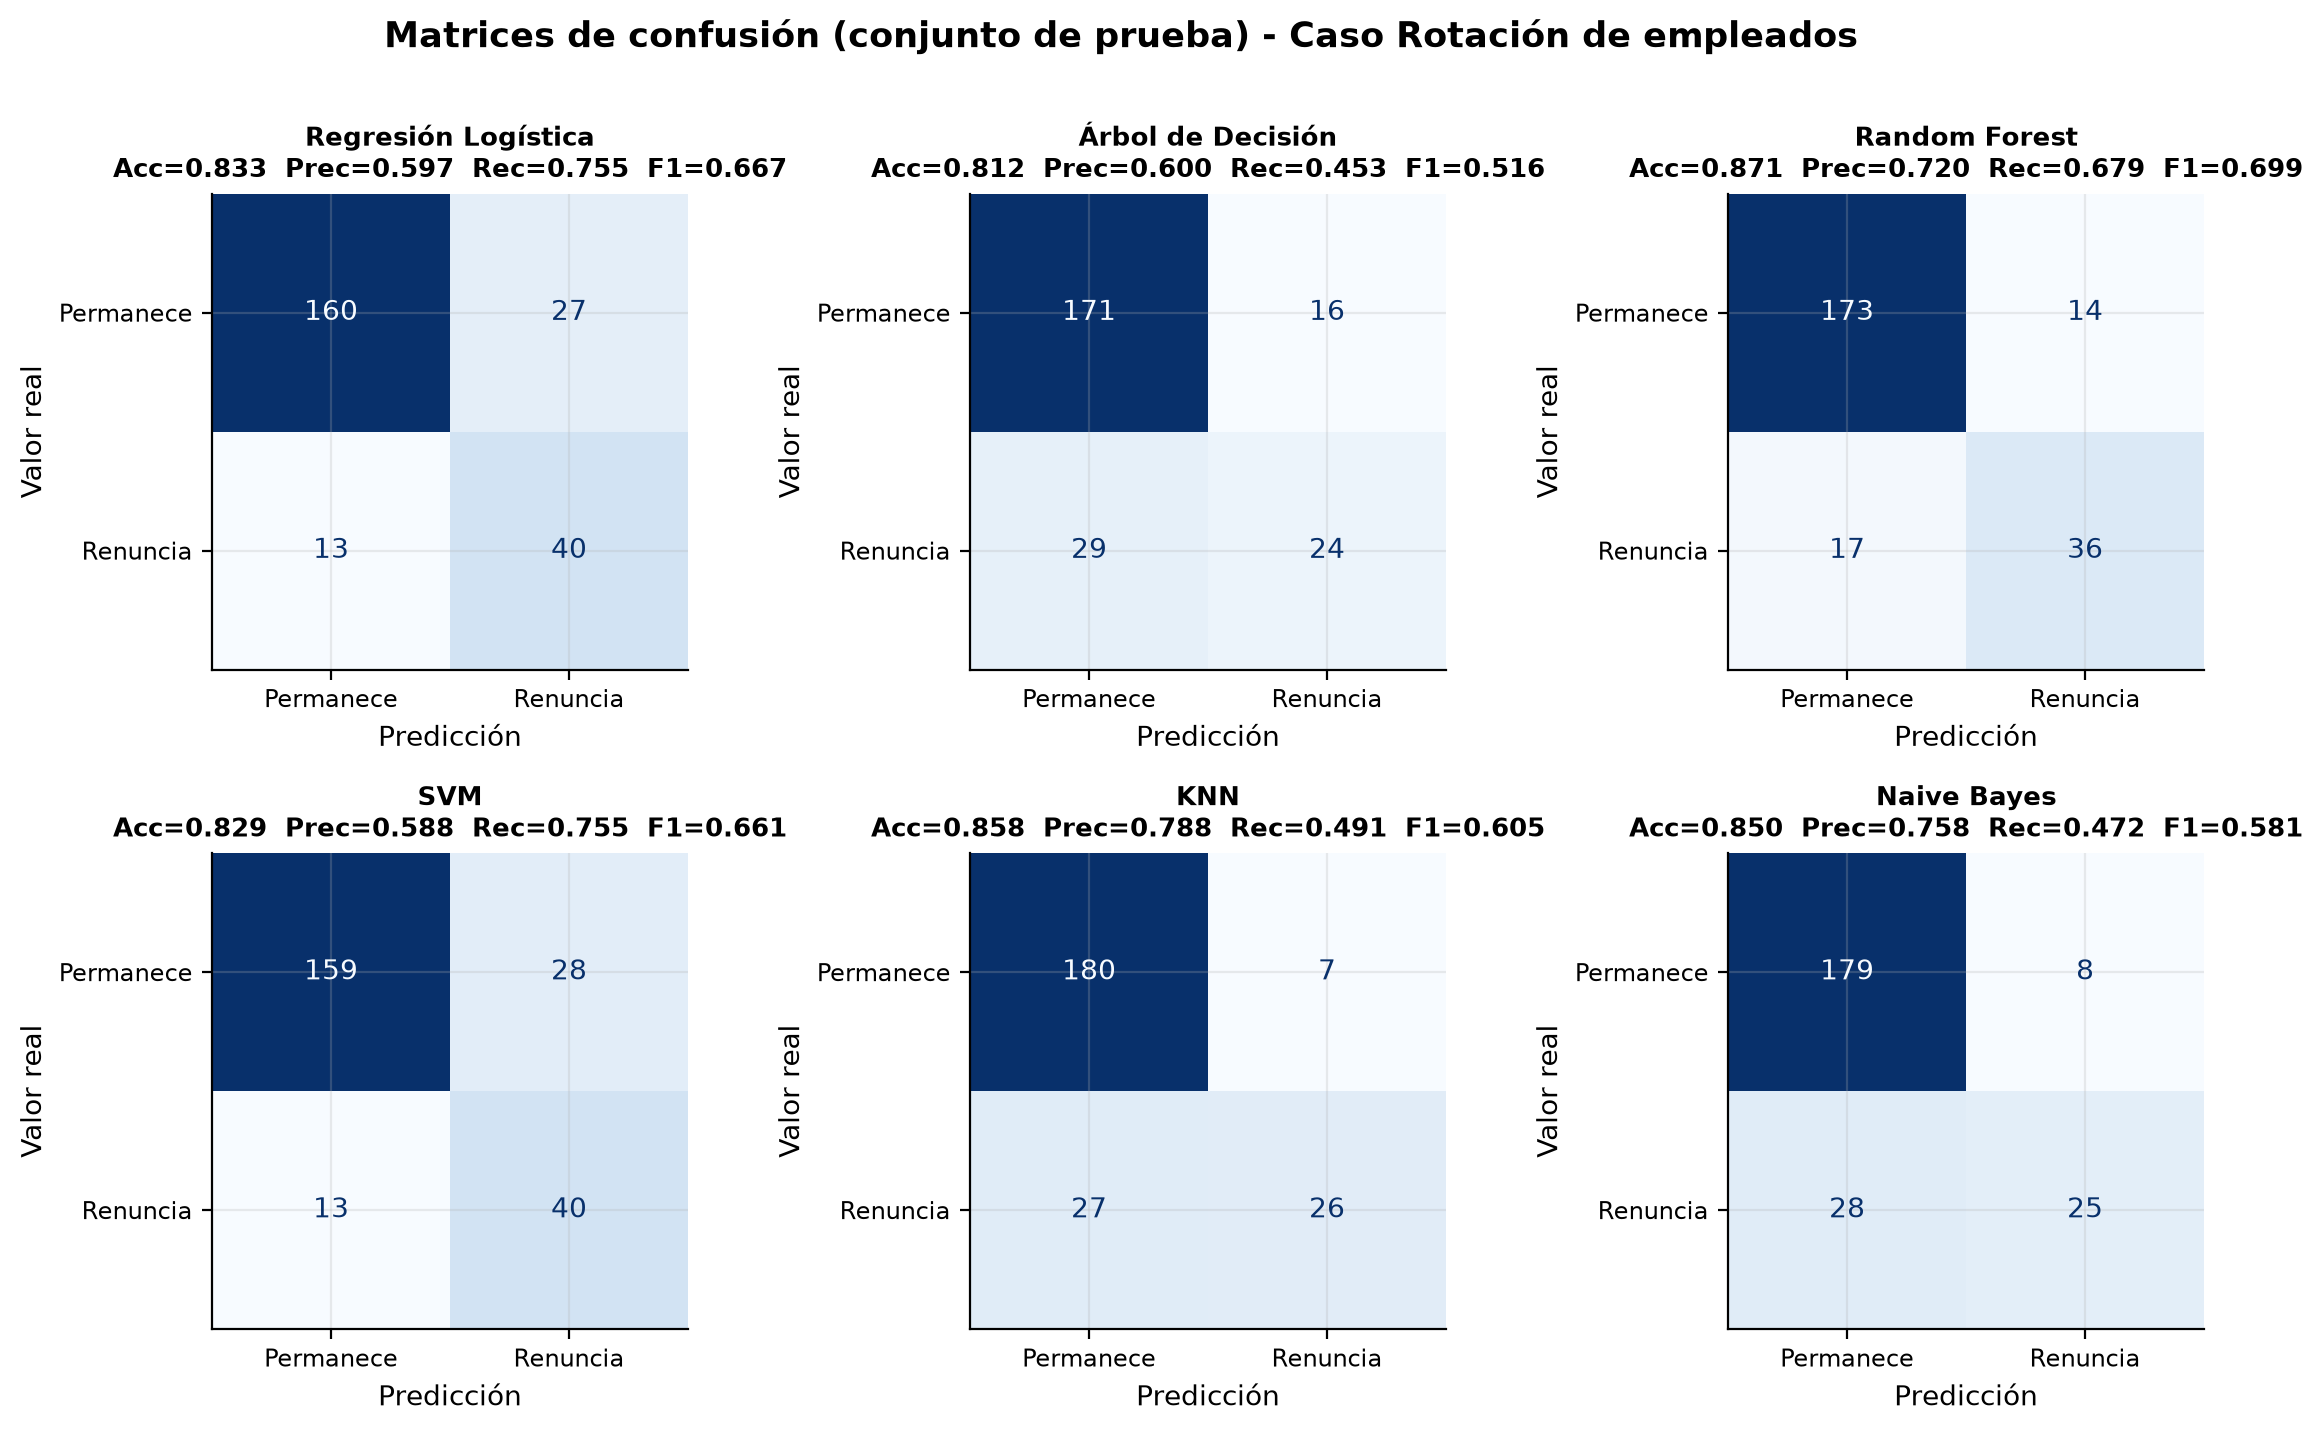

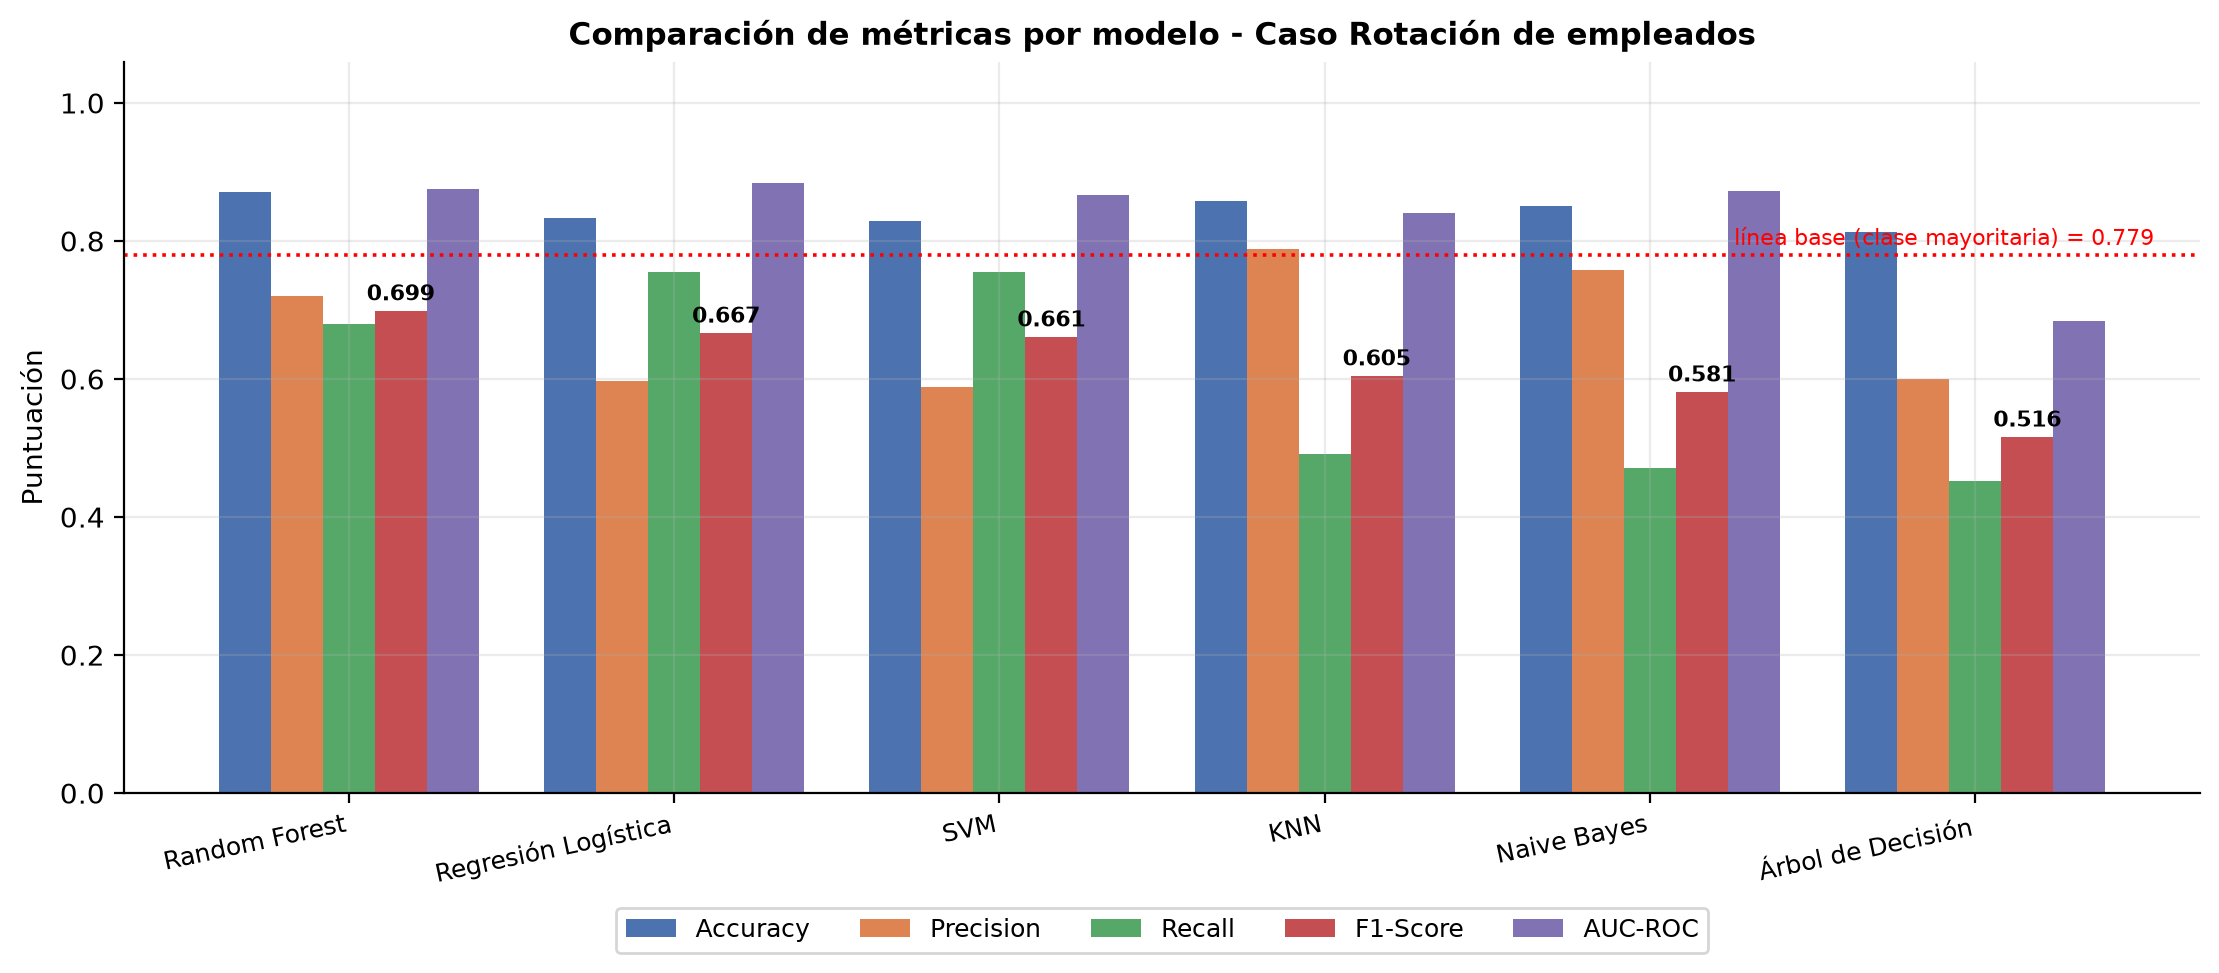

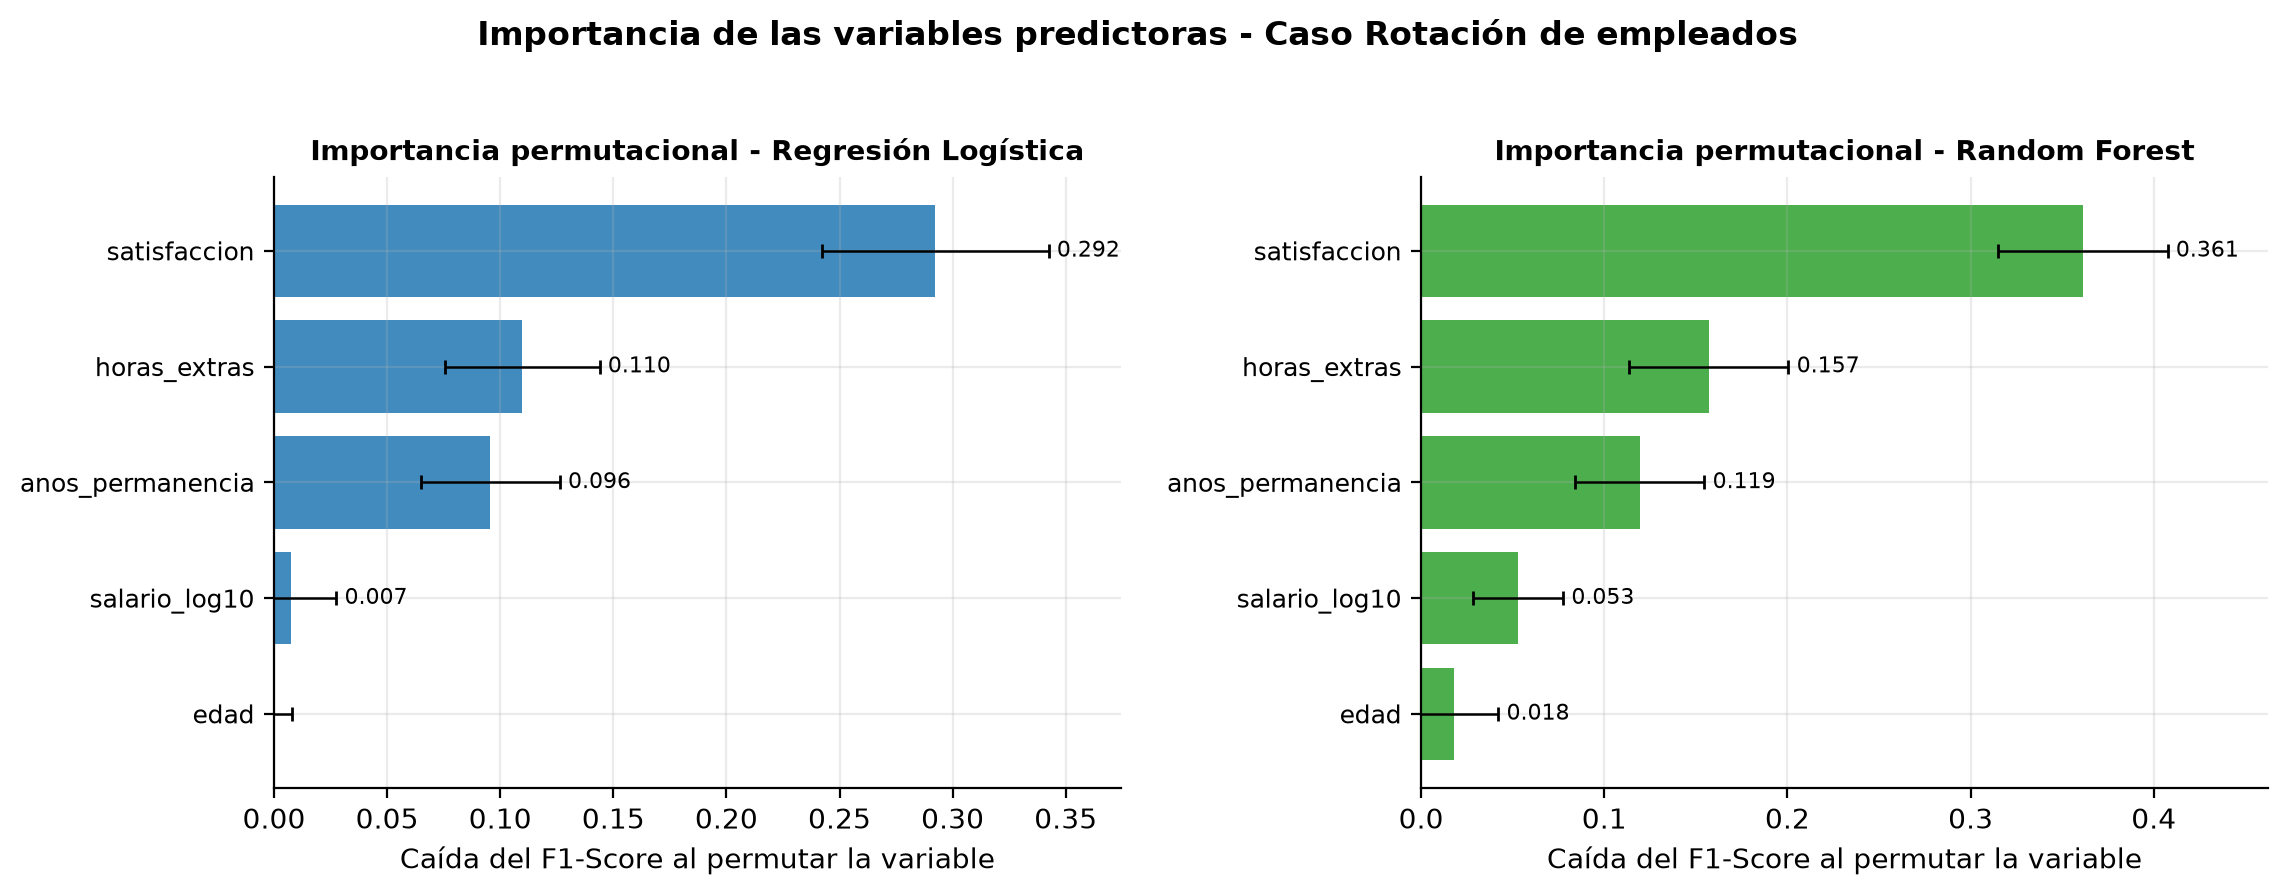

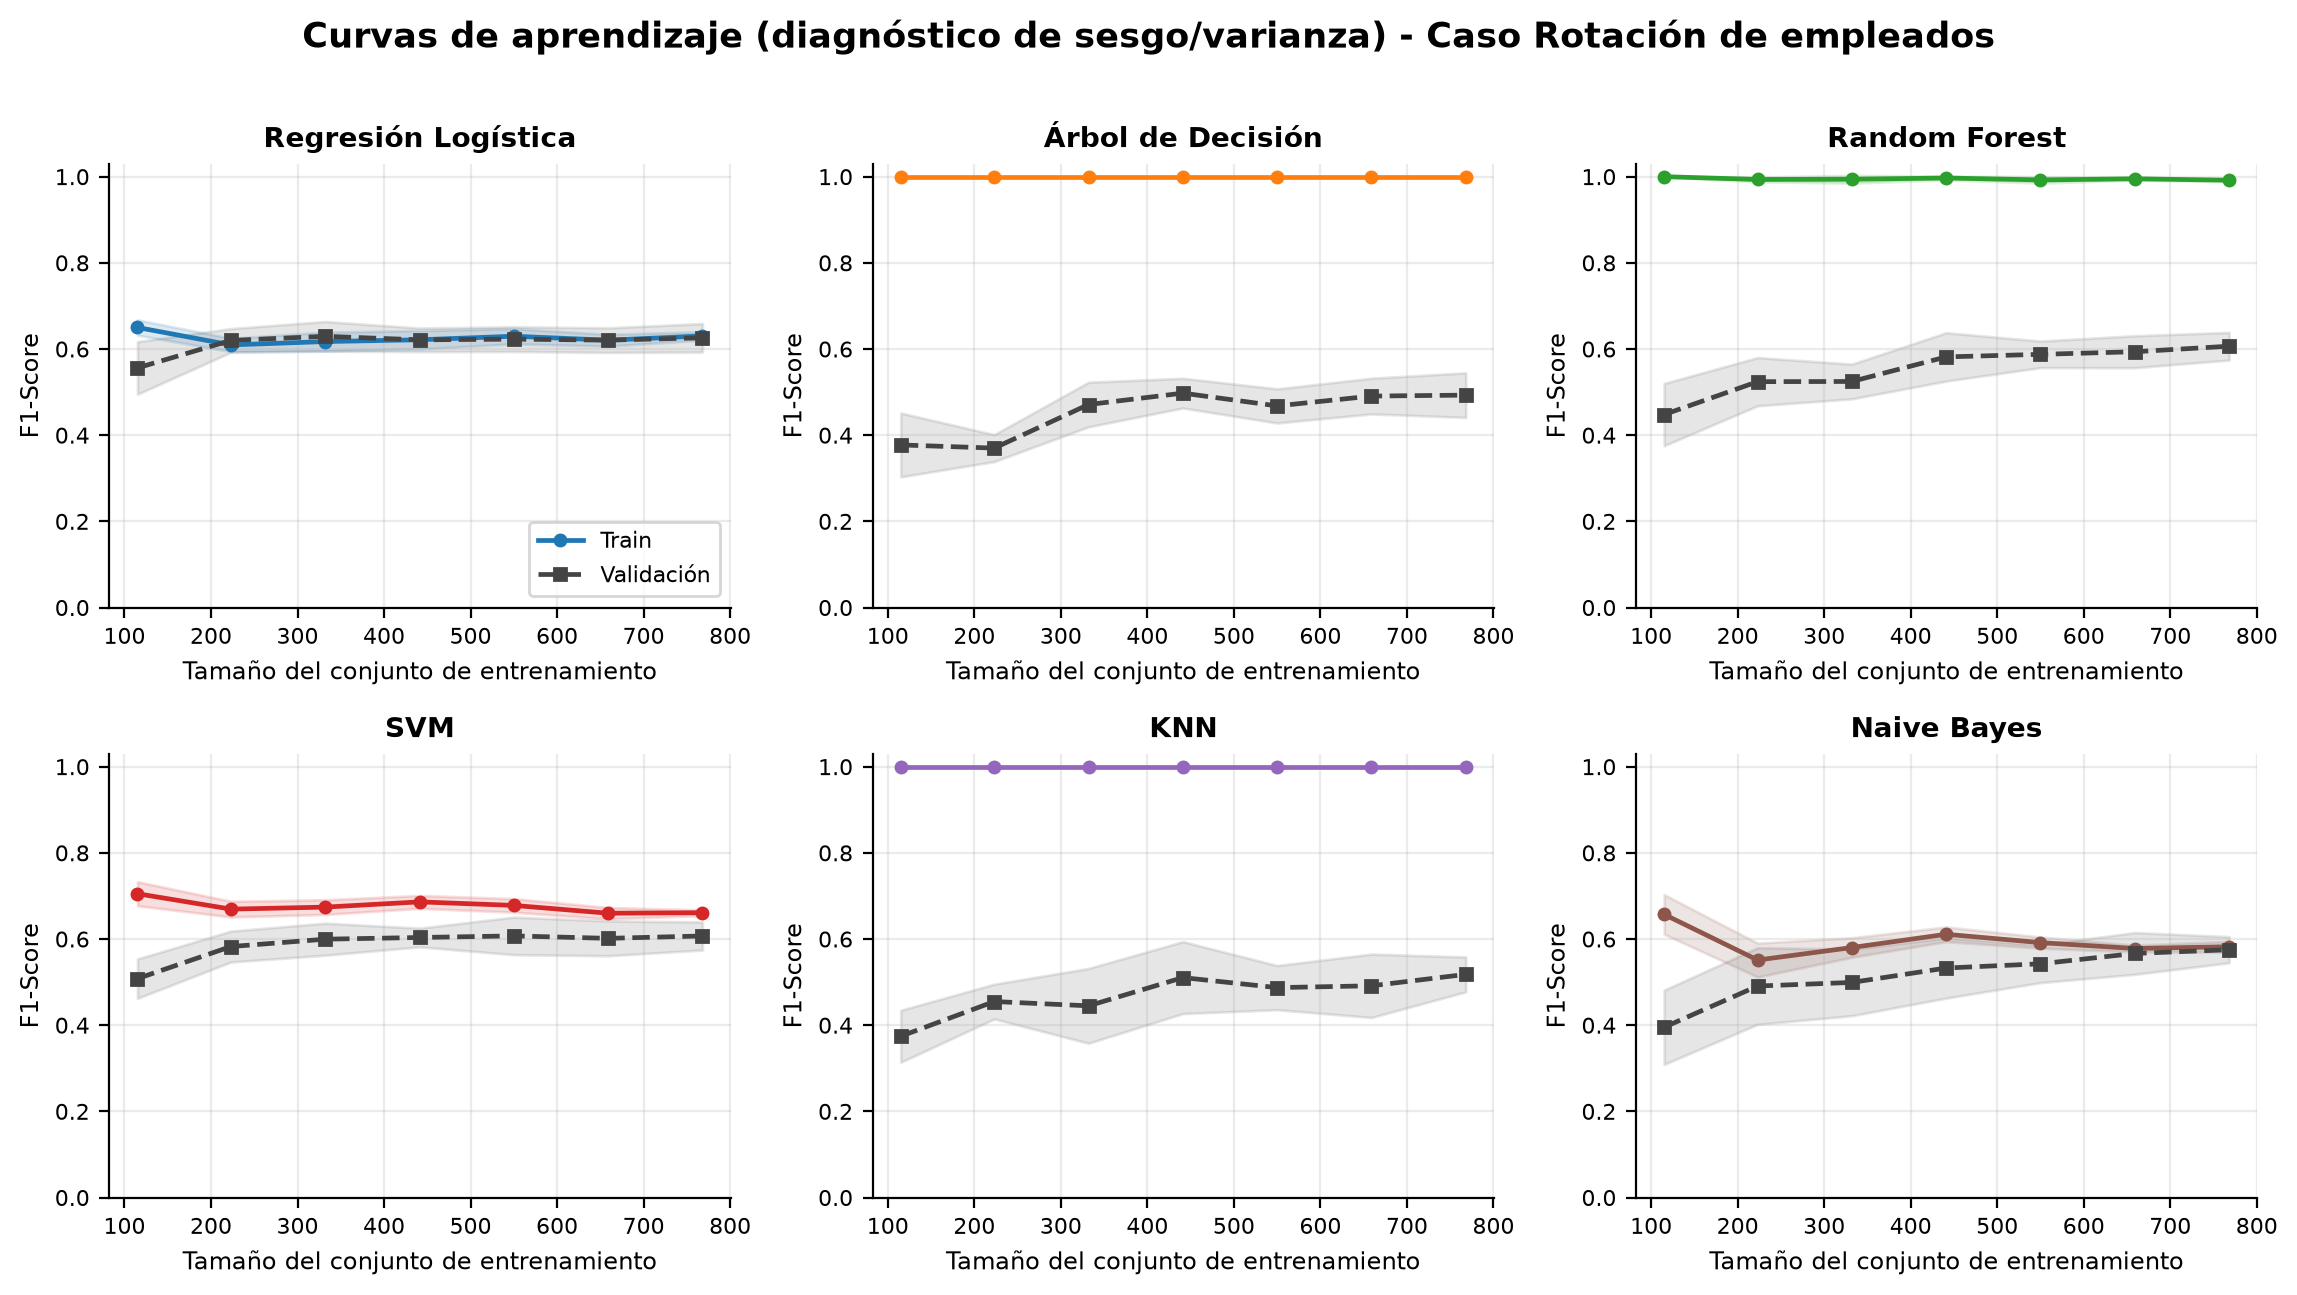

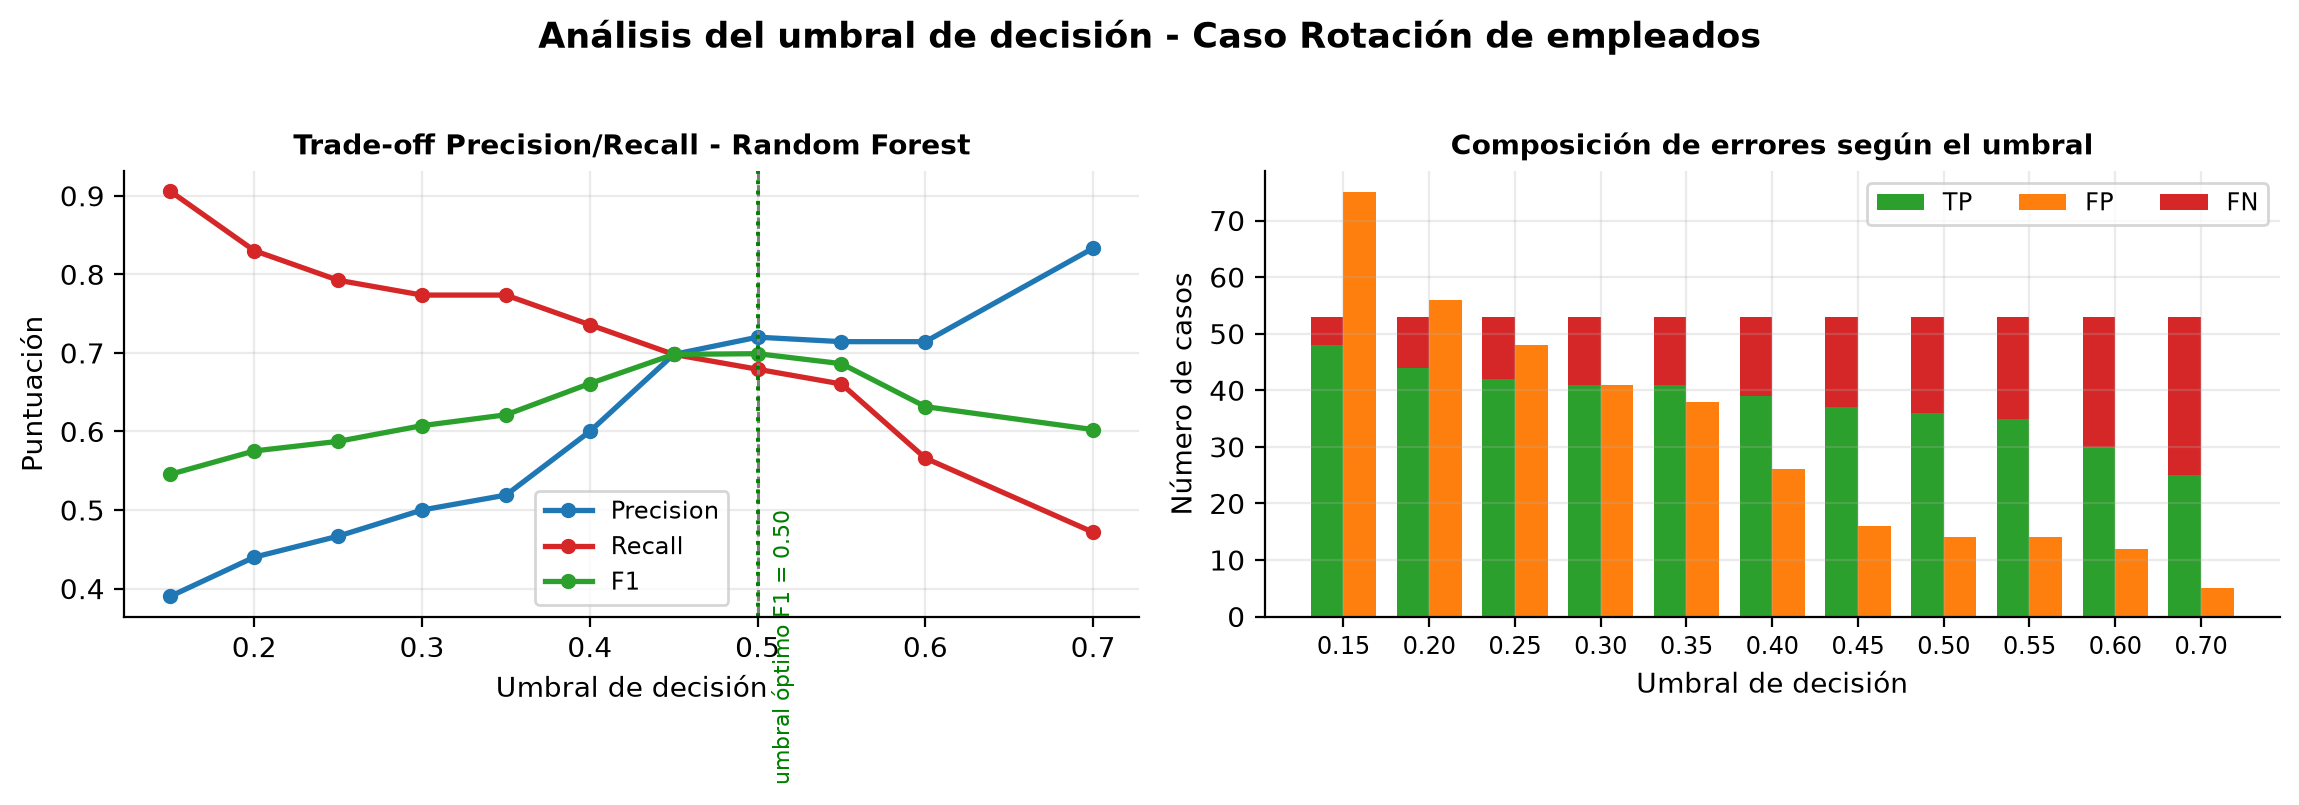

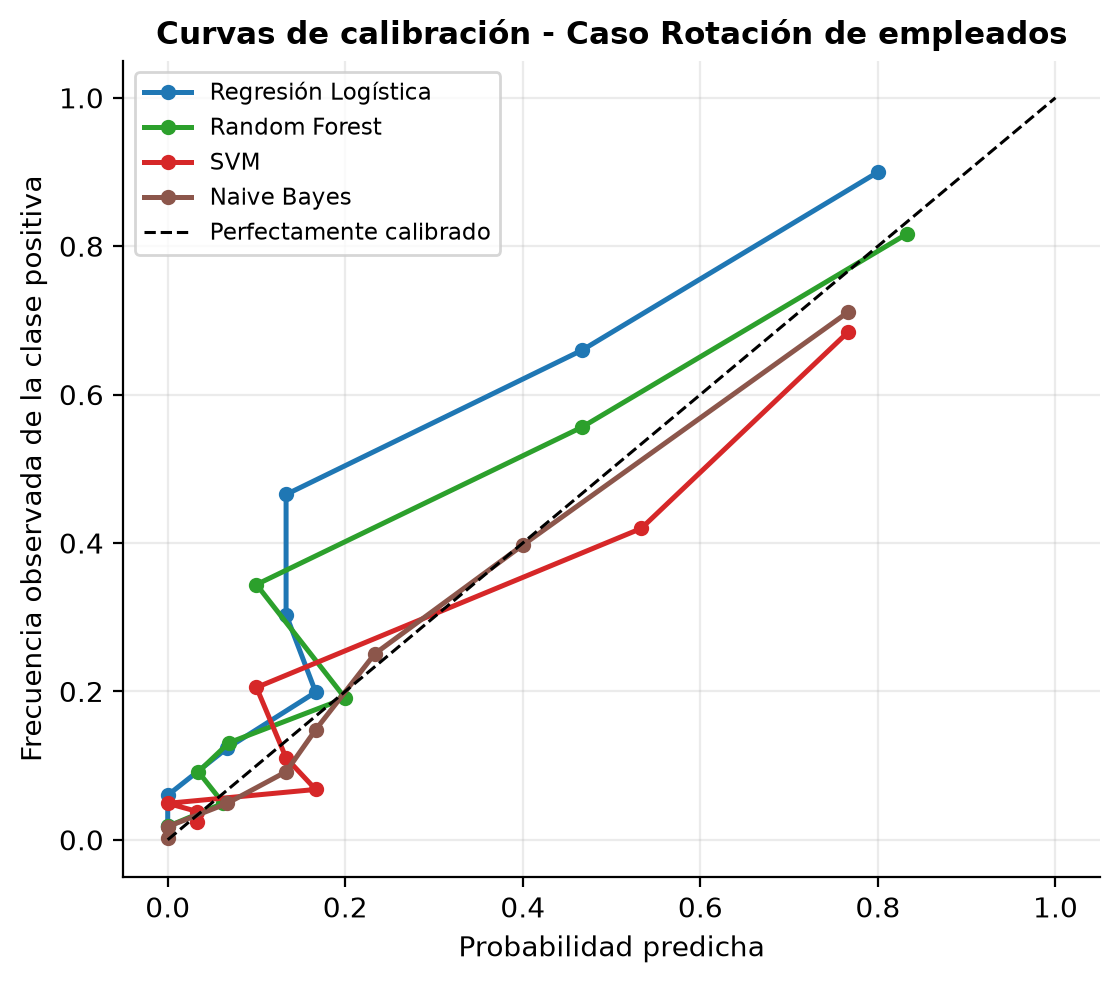

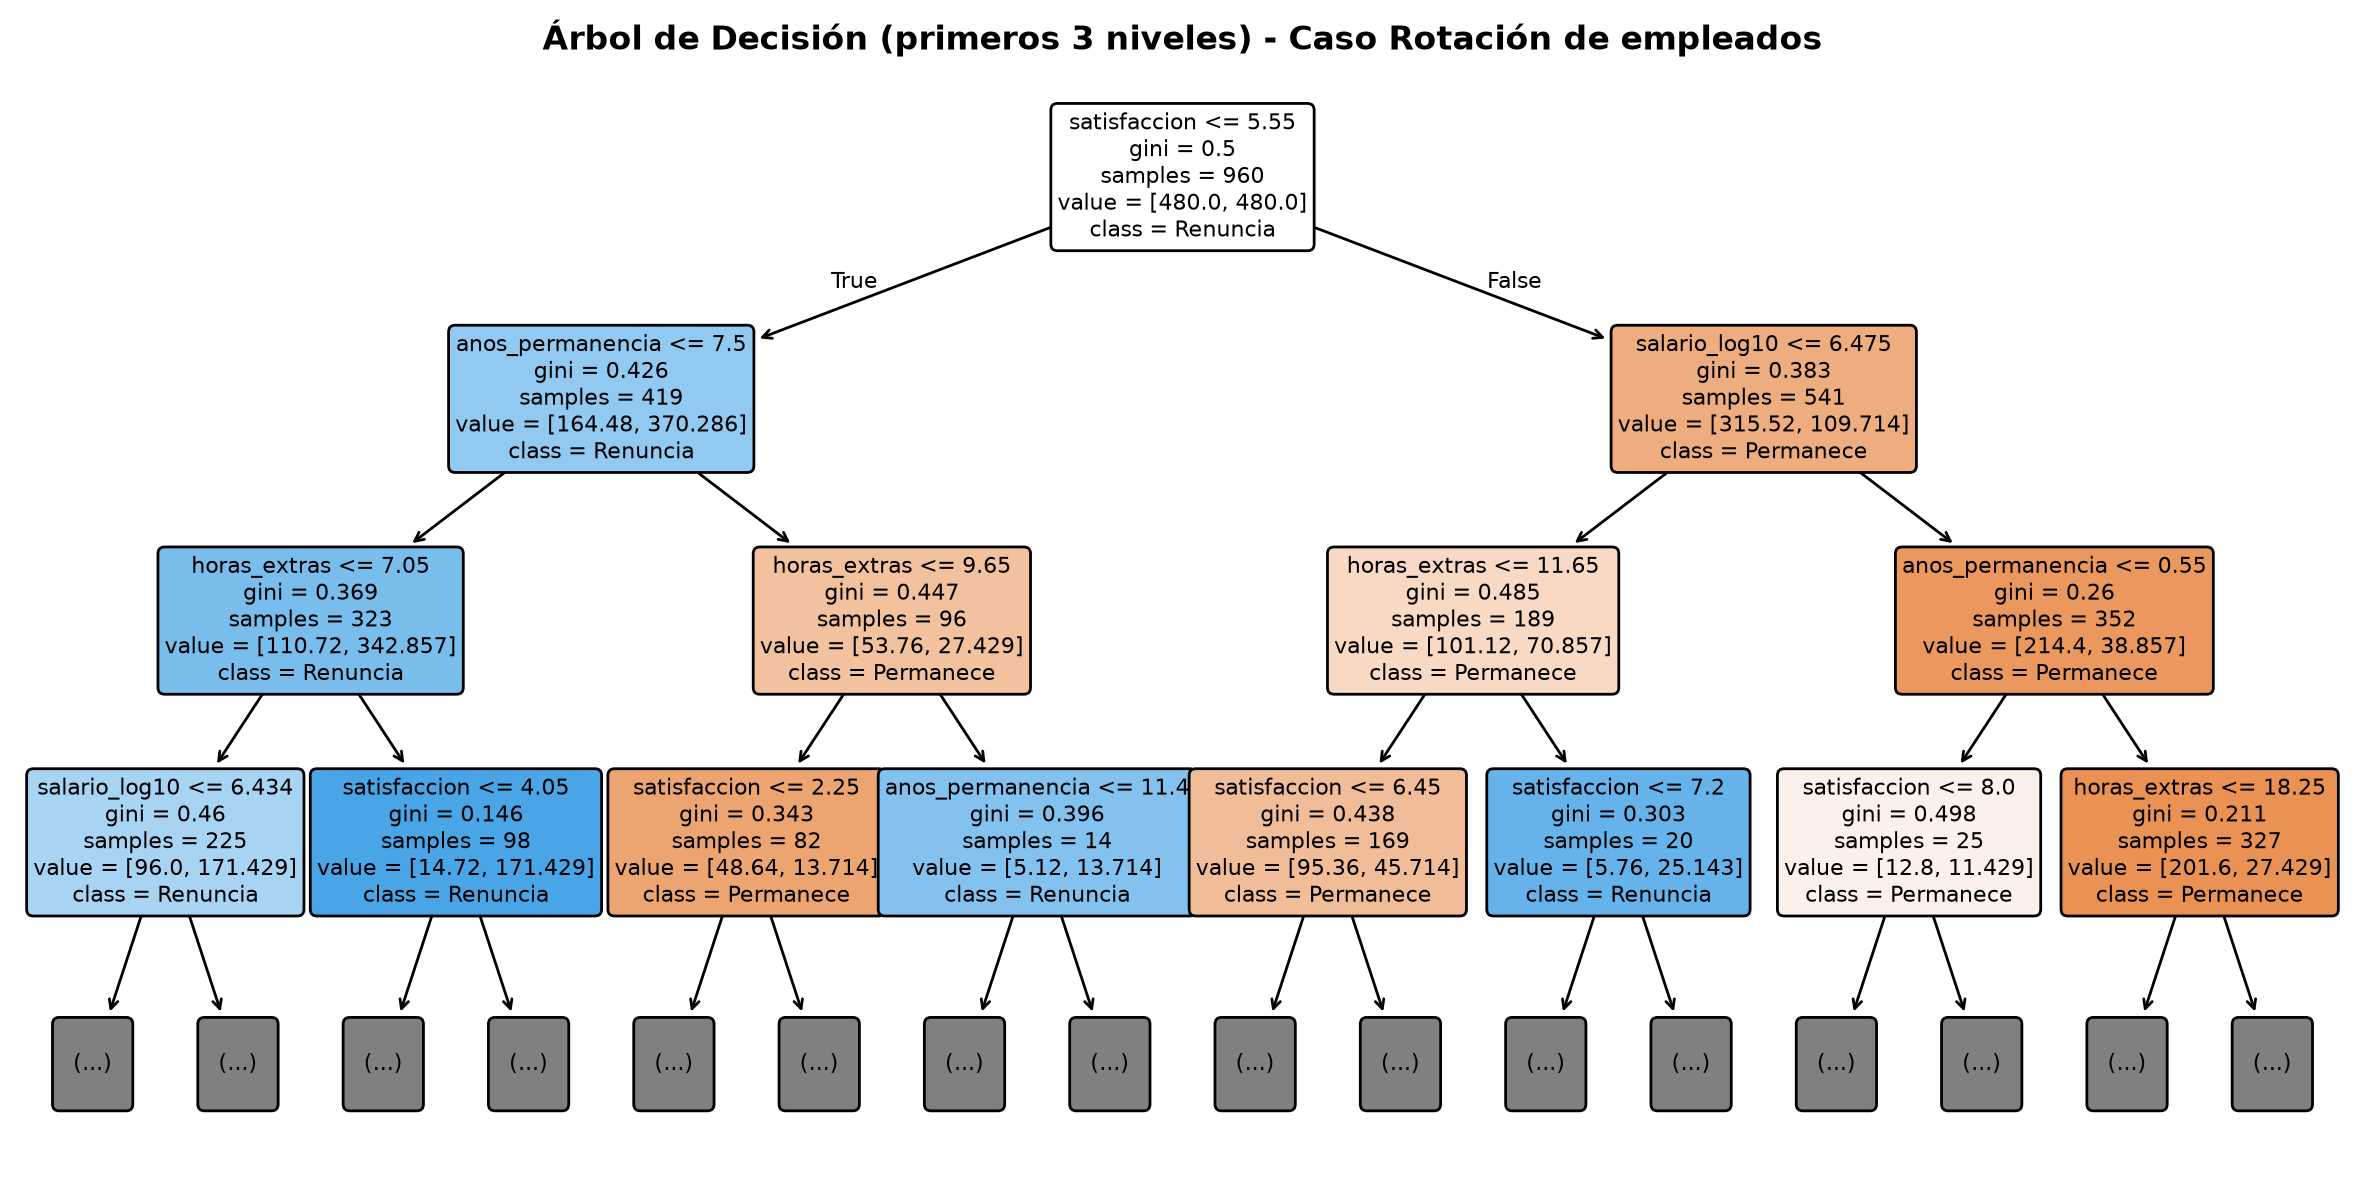

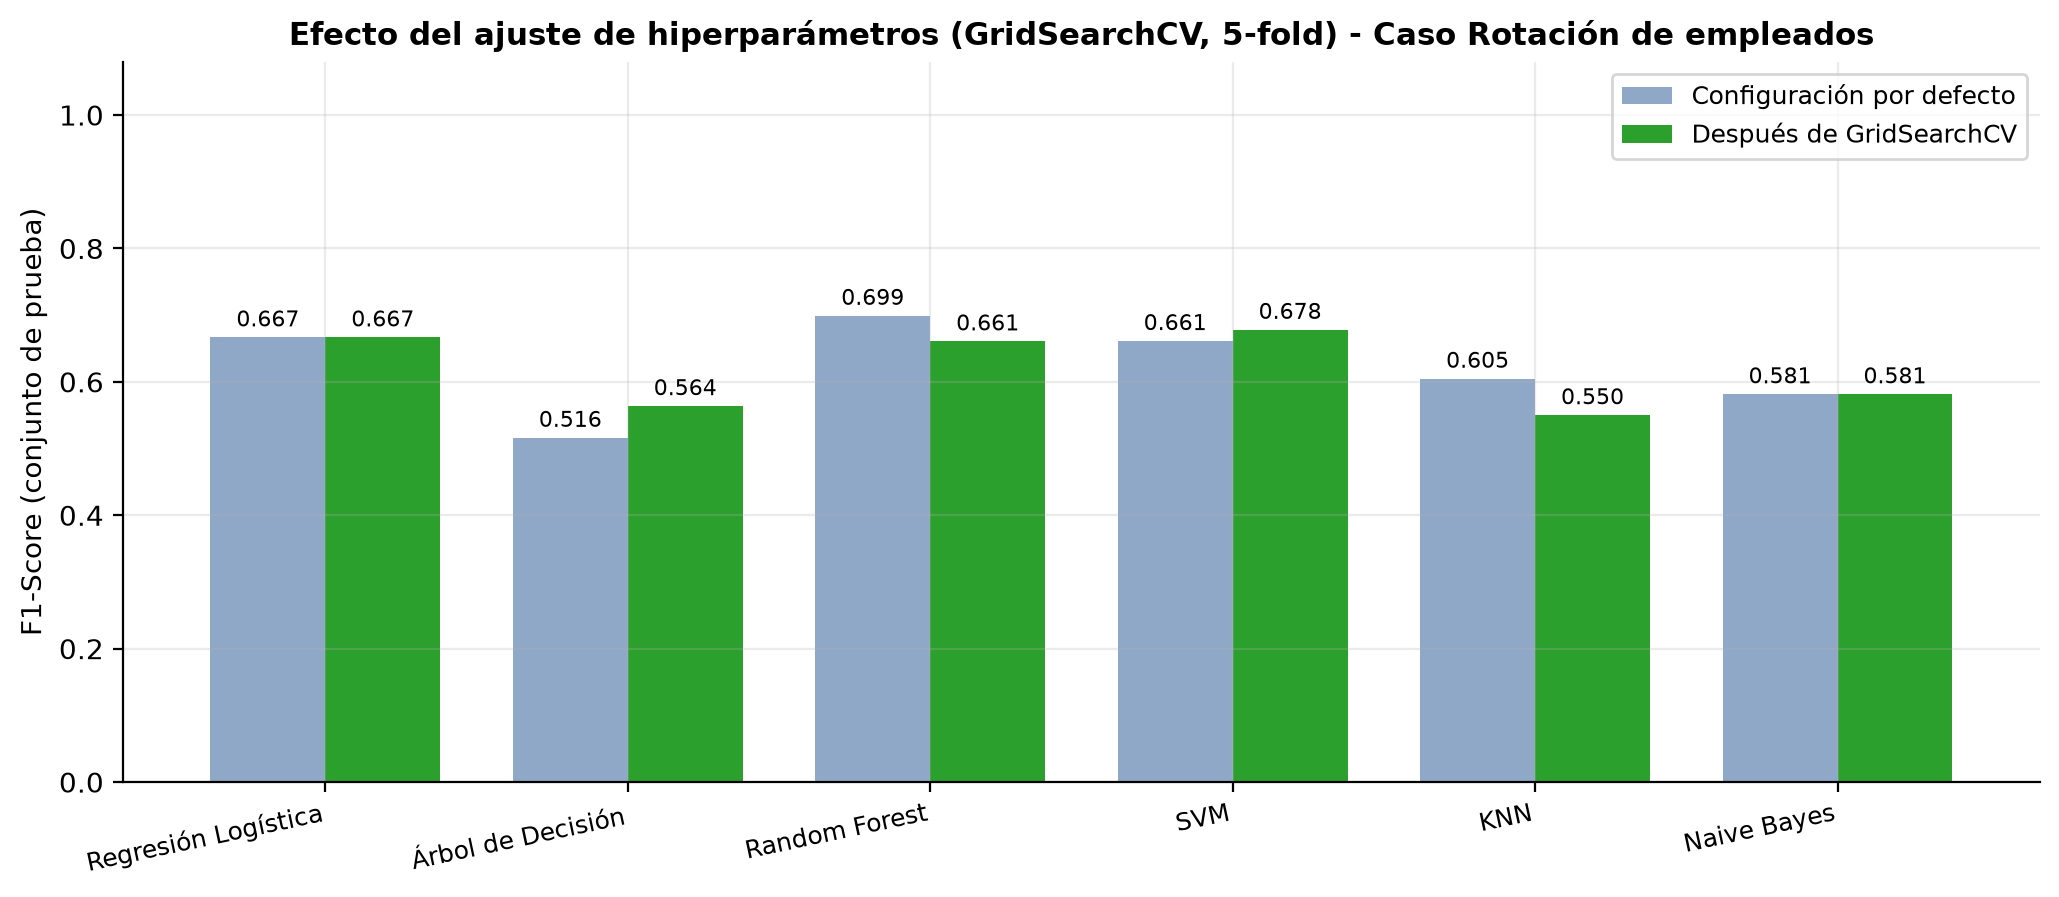

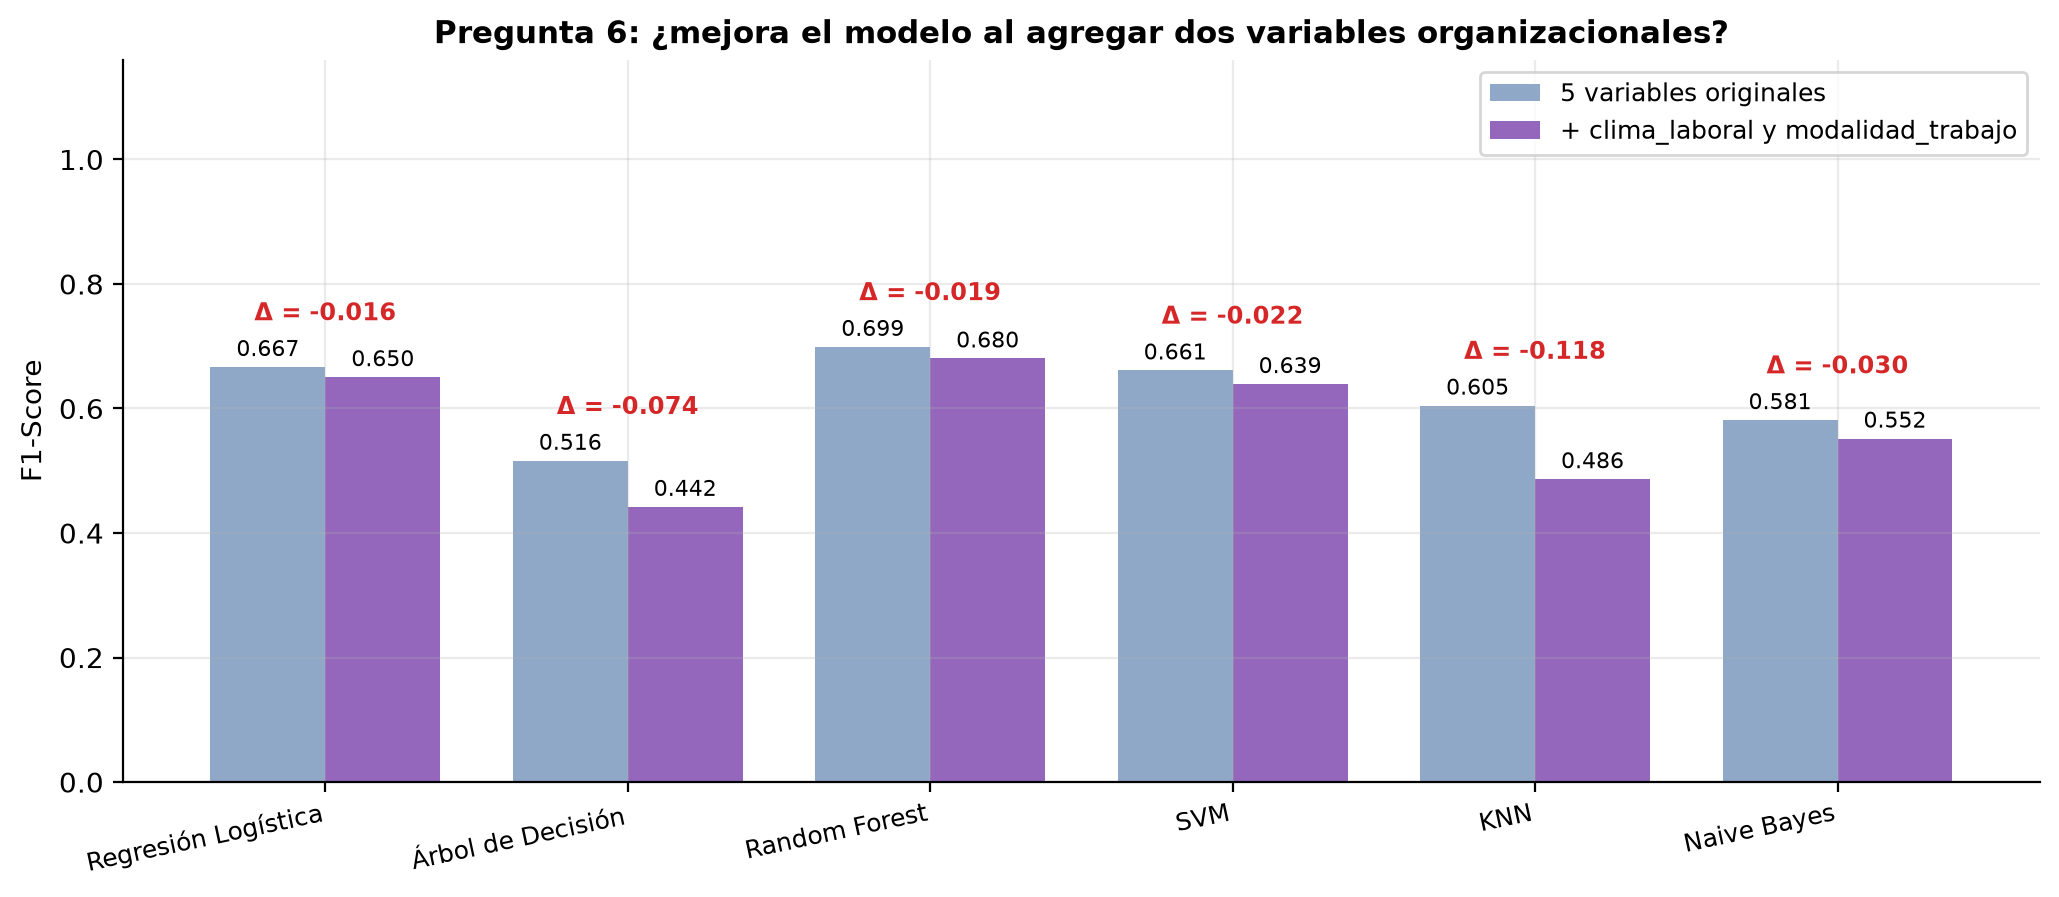

In [6]:
for f in sorted(DIR_FIGS.glob('rrhh_*.png')):
    display(Image(filename=str(f)))

## Experimento pregunta 6

In [7]:
p6 = res.extra['pregunta6']
comp = pd.DataFrame({'F1 base': {k:v['f1'] for k,v in p6['Modelo base (5 variables)'].items()}, 'F1 ampliado': {k:v['f1'] for k,v in p6['Modelo ampliado (+2 variables)'].items()}, 'AUC ampliado': {k:v['roc_auc'] for k,v in p6['Modelo ampliado (+2 variables)'].items()}})
comp['delta'] = (comp['F1 ampliado']-comp['F1 base']).round(3)
comp.round(3)

,F1 base,F1 ampliado,AUC ampliado,delta
Regresión Logística,0.667,0.650,0.906,-0.016
Árbol de Decisión,0.516,0.442,0.642,-0.074
Random Forest,0.699,0.680,0.885,-0.019
SVM,0.661,0.639,0.885,-0.022
KNN,0.605,0.486,0.831,-0.118
Naive Bayes,0.581,0.552,0.900,-0.030


In [8]:
for nombre, m in res.metricas.items():
    print('='*70); print(nombre); print('='*70); print(m['reporte'])

Regresión Logística
              precision    recall  f1-score   support

   Permanece      0.925     0.856     0.889       187
    Renuncia      0.597     0.755     0.667        53

    accuracy                          0.833       240
   macro avg      0.761     0.805     0.778       240
weighted avg      0.852     0.833     0.840       240

Árbol de Decisión
              precision    recall  f1-score   support

   Permanece      0.855     0.914     0.884       187
    Renuncia      0.600     0.453     0.516        53

    accuracy                          0.812       240
   macro avg      0.728     0.684     0.700       240
weighted avg      0.799     0.812     0.803       240

Random Forest
              precision    recall  f1-score   support

   Permanece      0.911     0.925     0.918       187
    Renuncia      0.720     0.679     0.699        53

    accuracy                          0.871       240
   macro avg      0.815     0.802     0.808       240
weighted avg      0.86

## Interpretación
* **Random Forest**: mejor F1 (0.699) y MCC (0.617).
* **Regresión logística**: mejor AUC (0.884) y odds ratios interpretables.
* **log10(salario)** evita que Naive Bayes degenere (F1 0.000 → 0.581).
* Clima laboral y modalidad mejoran el AUC: hay señal, pero exige recalibrar el umbral.
